# Lab 9- Deep Learning Model

This lab is meant to get you started in using Keras to design Deep Neural Networks. The goal here is to simply repeat your previous lab, but with DNNs.

Lecture 21 is your template: it reads the same data, builds, compiles and trains a network, plots its learning curves, and makes a ROC curve. Copy its cells and change the numbers.

Let's start with reading the data, like before. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, as in Lab 8. You will need both in Exercise 2.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

filename="../Lab.7/SUSY.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]

df = pd.read_csv(filename, dtype='float64', names=VarNames)
df.head()

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859


Now let's define the samples. DNNs take long to train, so to start we use only the first 500,000 of the 5 million events for training. Once you get everything working, make the final version of your plots with more.

We keep **three** samples, because they do different jobs:

* **training**: what `fit` learns from;
* **validation**: what you watch while you work (pass it to `fit` as `validation_data`), and what you use to choose between models;
* **test**: used only at the end, to report the performance of the models you chose.

Keras works on NumPy arrays, so after doing all of the nice manipulation that pandas enables, we convert the DataFrames to NumPy arrays.

In [6]:
N_Train=500000
N_Val=50000
N_Test=50000

Train_Sample=df[:N_Train]
Val_Sample=df[N_Train:N_Train+N_Val]
Test_Sample=df[N_Train+N_Val:N_Train+N_Val+N_Test]

X_Train=np.array(Train_Sample[VarNames[1:]])
y_Train=np.array(Train_Sample["signal"])

X_Val=np.array(Val_Sample[VarNames[1:]])
y_Val=np.array(Val_Sample["signal"])

X_Test=np.array(Test_Sample[VarNames[1:]])
y_Test=np.array(Test_Sample["signal"])

print(X_Train.shape, X_Val.shape, X_Test.shape)

(500000, 18) (50000, 18) (50000, 18)


## Exercise 1

You will need to create several models and make sure they are properly trained. Write a function that takes this history and plots the values versus epoch. For every model that you train in the remainder of this lab, assess:

* Has your model's performance plateaued? If not train for more epochs. 
* Compare the performance on the training and validation samples. Are you over training?

In [9]:
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense

#creating a network
keras.utils.set_random_seed(42)

inputs = Input(shape = (X_Train.shape[1],)) #each events has 18 measurements

x = Dense(12, activation = "relu")(inputs)#layer of 12 neurons each receiving all inputs from previous layer
x = Dense(8, activation = "relu")(x) #Dense(8) layers transform the information using eight neurons each
x = Dense(8, activation = "relu")(x) #"relu" lets the negative values be 0 and positive unchanged

outputs = Dense(1, activation = "sigmoid")(x) #this produces 1 score between 0 and 1

model = Model(inputs = inputs, outputs = outputs) #connecting the inputs with outputs
model.summary()

#configuring and training the model
model.compile

E0000 00:00:1794016152.339069     899 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 18)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │           228 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 413 (1.61 KB)

 Trainable params: 413 (1.61 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
#configuring learning and training the model
model.compile(
    loss = "binary_crossentropy", #loss measures prediction error; binary cross-entrophy suits 2 classes abd sigmoid output
    optimizer = "adam", #adam adjusts weights and biases to reduce loss
    metrics = ["accuracy"] #accuracy reports the fraction classified correctly using a threshold of 0.5 which is monitored, the loss drives learning
)

#training the model
history = model.fit( #history means store the training and validation results for every epoch
    X_Train,
    y_Train,
    validation_data = (X_Val, y_Val),
    epochs = 10, #make ten passes through training dataset
    batch_size = 2048 #process upto 2048 training events before weight update
)

Epoch 1/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6430 - loss: 0.6040 - val_accuracy: 0.7834 - val_loss: 0.5107
Epoch 2/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7904 - loss: 0.4637 - val_accuracy: 0.7900 - val_loss: 0.4545
Epoch 3/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7946 - loss: 0.4480 - val_accuracy: 0.7926 - val_loss: 0.4485
Epoch 4/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7962 - loss: 0.4437 - val_accuracy: 0.7940 - val_loss: 0.4450
Epoch 5/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7974 - loss: 0.4407 - val_accuracy: 0.7951 - val_loss: 0.4424
Epoch 6/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7980 - loss: 0.4387 - val_accuracy: 0.7956 - val_loss: 0.4408
Epoch 7/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7985 - loss: 0.4376 - val_accuracy: 0.7958 - val_loss: 0.4398
Epoch 8/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7988 - loss: 0.4368 - val_accuracy: 0.

In [18]:
def plot_history(history, title):
    values = history.history
    epochs = np.arange(1, len(values["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize = (10, 6))

    #the lower the loss is, its better
    axes[0].plot(epochs, values["loss"], label = "Training")
    axes[0].plot(epochs, values["val_loss"], label = "Validation")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend(loc = "best")

    #the higher the accuracy its better
    axes[1].plot(epochs, values["accuracy"], label = "Training")
    axes[1].plot(epochs, values["val_accuracy"], label = "Validation")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend(loc = "best")

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

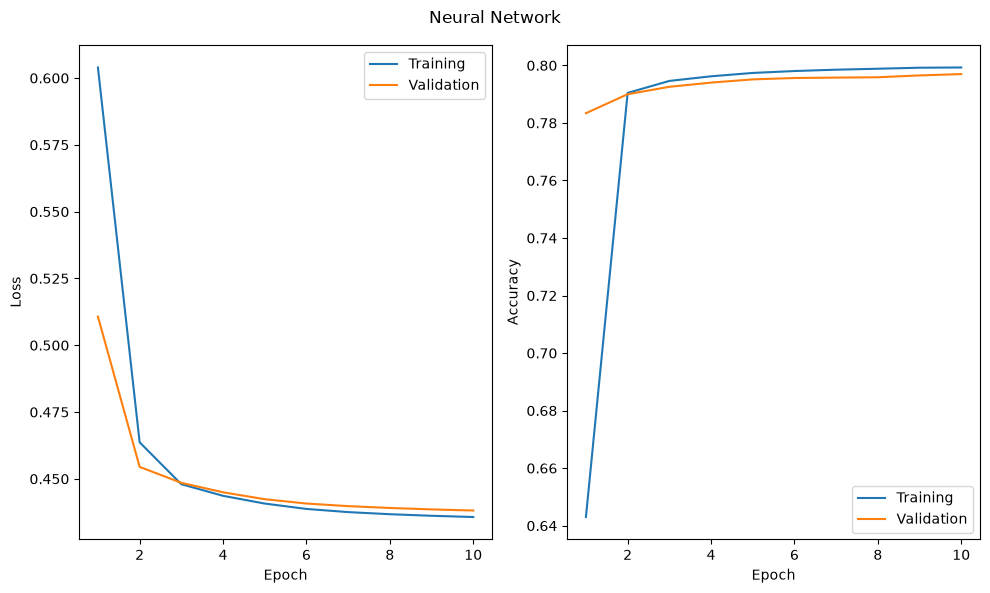

In [19]:
plot_history(history, "Neural Network")

Epoch 11/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7996 - loss: 0.4353 - val_accuracy: 0.7972 - val_loss: 0.4378
Epoch 12/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7997 - loss: 0.4349 - val_accuracy: 0.7972 - val_loss: 0.4374
Epoch 13/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7999 - loss: 0.4346 - val_accuracy: 0.7973 - val_loss: 0.4371
Epoch 14/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8000 - loss: 0.4343 - val_accuracy: 0.7975 - val_loss: 0.4369
Epoch 15/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8001 - loss: 0.4341 - val_accuracy: 0.7977 - val_loss: 0.4366
Epoch 16/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8002 - loss: 0.4339 - val_accuracy: 0.7980 - val_loss: 0.4364
Epoch 17/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8002 - loss: 0.4337 - val_accuracy: 0.7981 - val_loss: 0.4362
Epoch 18/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8002 - loss: 0.4335 - val_accu

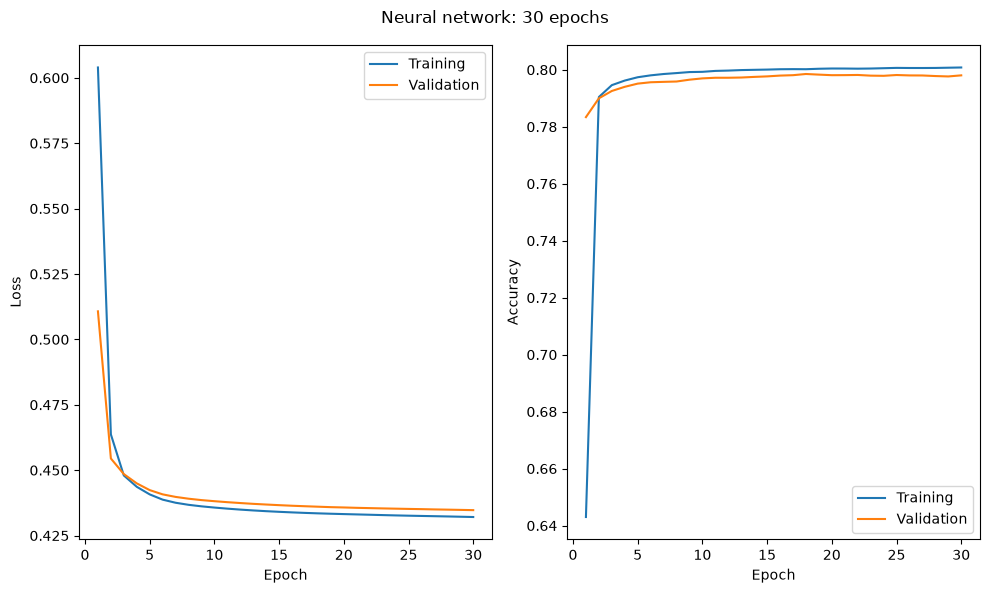

In [20]:
#Here, the model looks nearly plateaued, but for more confirmation, let's add extra epochs
extra_history = model.fit(
    X_Train,
    y_Train, 
    validation_data = (X_Val, y_Val),
    initial_epoch = 10, #means instead of rerunning again from 1 it runs from 11 to 30
    epochs = 30,
    batch_size = 2048
)
for key in history.history:
    history.history[key].extend(extra_history.history[key])

plot_history(history, "Neural network: 30 epochs")

Training and validation loss decreased rapidly during the first few epochs and approached a plateau by 30 epochs. The curves remained close, with no clear sign of overfitting. Further training appears likely to provide only small improvements for this architecture.

## Exercise 2

Following the original paper (see Lab 7), make a comparison of the performance (using ROC curves and AUC) between models trained with the raw quantities (`RawNames`), the derived features (`FeatureNames`), and both. Note that the first layer's input shape changes with the number of inputs.

In [21]:
def build_model(n_inputs):
    inputs = Input(shape = (n_inputs,))

    x = Dense(12, activation = "relu")(inputs)
    x = Dense(8, activation = "relu")(x)
    x = Dense(8, activation = "relu")(x)

    outputs = Dense(1, activation = "sigmoid")(x)

    model = Model(inputs = inputs, outputs = outputs)

    model.compile(
        loss = "binary_crossentropy",
        optimizer = "adam",
        metrics = ["accuracy"]
    )

    return model

In [22]:
raw_model = build_model(len(RawNames))
raw_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 12)             │           108 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 293 (1.14 KB)

 Trainable params: 293 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6338 - loss: 0.6151 - val_accuracy: 0.7640 - val_loss: 0.5000
Epoch 2/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7711 - loss: 0.4878 - val_accuracy: 0.7719 - val_loss: 0.4874
Epoch 3/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7743 - loss: 0.4829 - val_accuracy: 0.7748 - val_loss: 0.4835
Epoch 4/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7765 - loss: 0.4788 - val_accuracy: 0.7766 - val_loss: 0.4790
Epoch 5/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7778 - loss: 0.4749 - val_accuracy: 0.7774 - val_loss: 0.4751
Epoch 6/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7789 - loss: 0.4714 - val_accuracy: 0.7788 - val_loss: 0.4715
Epoch 7/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7800 - loss: 0.4684 - val_accuracy: 0.7804 - val_loss: 0.4687
Epoch 8/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7810 - loss: 0.4661 - val_accuracy: 0.

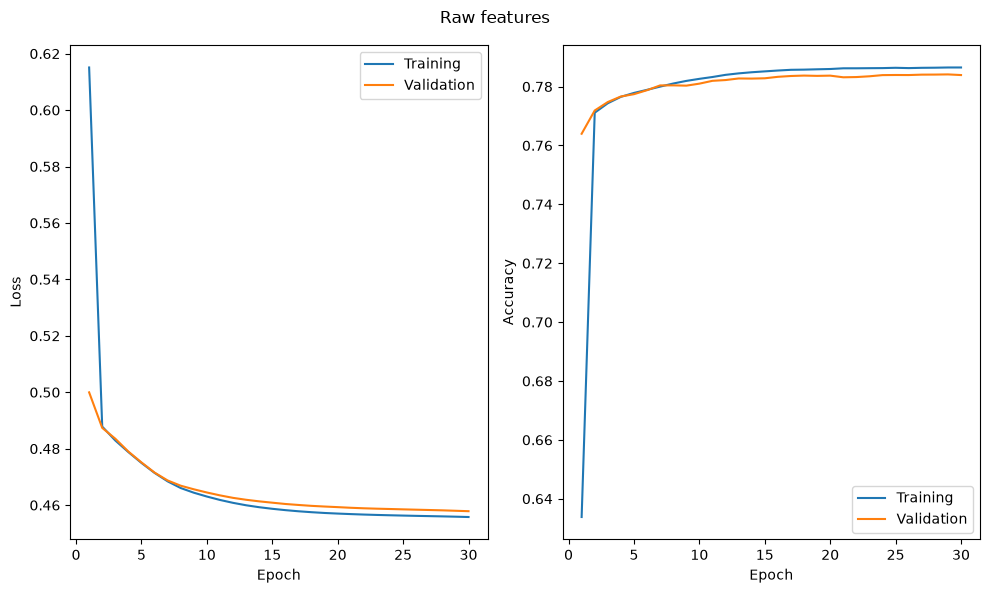

In [23]:
#training the model with only raw_features
X_Train_raw = np.array(Train_Sample[RawNames])
X_Val_raw = np.array(Val_Sample[RawNames])

raw_history = raw_model.fit(
    X_Train_raw,
    y_Train,
    validation_data = (X_Val_raw, y_Val),
    epochs = 30,
    batch_size = 2048
)
plot_history(raw_history, "Raw features")

In [24]:
#ROC Curve for raw_features
from sklearn.metrics import roc_curve, auc

raw_val_scores = raw_model.predict(X_Val_raw, batch_size = 2048, verbose = 0).ravel()

fpr_raw, tpr_raw, thresholds_raw = roc_curve(y_Val, raw_val_scores)
auc_raw = auc(fpr_raw, tpr_raw)

print("Raw features validation AUC: ", auc_raw)

Raw features validation AUC:  0.8568694036123988


Epoch 1/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7010 - loss: 0.5789 - val_accuracy: 0.7712 - val_loss: 0.4908
Epoch 2/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7796 - loss: 0.4744 - val_accuracy: 0.7796 - val_loss: 0.4712
Epoch 3/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7837 - loss: 0.4643 - val_accuracy: 0.7821 - val_loss: 0.4660
Epoch 4/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7853 - loss: 0.4606 - val_accuracy: 0.7829 - val_loss: 0.4630
Epoch 5/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7865 - loss: 0.4584 - val_accuracy: 0.7835 - val_loss: 0.4613
Epoch 6/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7871 - loss: 0.4570 - val_accuracy: 0.7840 - val_loss: 0.4603
Epoch 7/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7875 - loss: 0.4560 - val_accuracy: 0.7845 - val_loss: 0.4597
Epoch 8/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7879 - loss: 0.4553 - val_accuracy: 0.

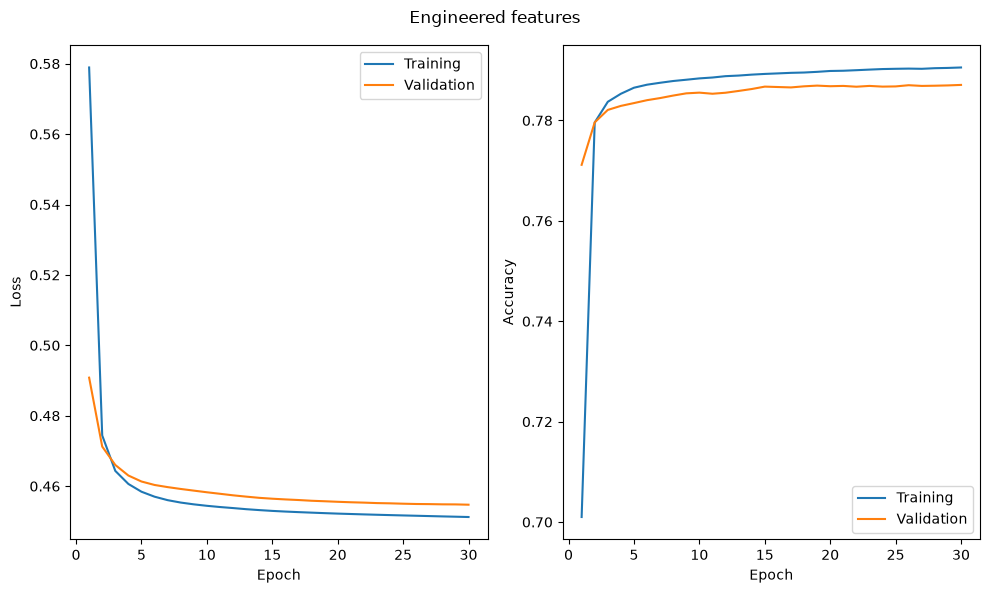

In [27]:
#training the model for engineered features
X_Train_engineered = np.array(Train_Sample[FeatureNames])
X_Val_engineered = np.array(Val_Sample[FeatureNames])

#creating a fresh model with 10 inputs
engineered_model = build_model(len(FeatureNames))

#Training the model
engineered_history = engineered_model.fit(
    X_Train_engineered,
    y_Train,
    validation_data = (X_Val_engineered, y_Val),
    epochs = 30,
    batch_size = 2048
)

#inspecting the learning curves
plot_history(engineered_history, "Engineered features")

In [28]:
#calculating the roc auc for engineered features

engineered_val_scores = engineered_model.predict(X_Val_engineered, batch_size = 2048, verbose = 0).ravel()

fpr_engineered, tpr_engineered, thresholds_engineered = roc_curve(y_Val, engineered_val_scores)
auc_engineered = auc(fpr_engineered, tpr_engineered)

print("Engineered features validation AUC: ", auc_engineered)


Engineered features validation AUC:  0.8574461369130872


In [29]:
#for all_features
all_model = model

all_val_scores = all_model.predict(X_Val, batch_size = 2048, verbose = 0).ravel()

fpr_all, tpr_all, thresholds_all = roc_curve(y_Val, all_val_scores)
auc_all = auc(fpr_all, tpr_all)

print("All features validation AUC: ", auc_all)

All features validation AUC:  0.8714204145378314


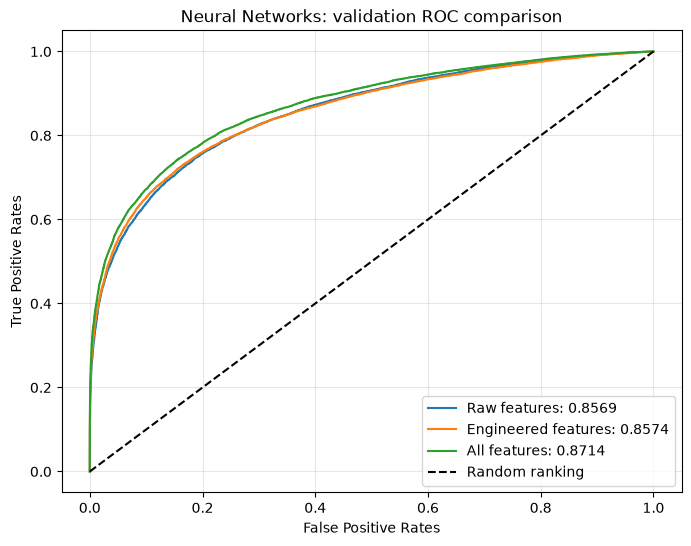

In [37]:
#Comparing all three ROC CURVES
plt.figure(figsize = (8,6))

plt.plot(fpr_raw, tpr_raw, label = f"Raw features: {auc_raw:.4f}")
plt.plot(fpr_engineered, tpr_engineered, label = f"Engineered features: {auc_engineered:.4f}")
plt.plot(fpr_all, tpr_all, label = f"All features: {auc_all:.4f}")

plt.plot([0,1], [0,1], "k--", label = "Random ranking")

plt.xlabel("False Positive Rates")
plt.ylabel("True Positive Rates")
plt.title("Neural Networks: validation ROC comparison")
plt.legend(loc = "best")
plt.grid(alpha = 0.3)
plt.show()

Raw and engineered features produced very similar validation AUCs. Combining both groups increased AUC to 0.8714 which gives the best ranking performance among these three models. 

## Exercise 3

Design and implement at least 3 different DNN models. Train them and compare performance. You may try different architectures, loss functions, and optimizers to see if there is an effect.

In [41]:
#Here we will use already trained model with hidden layer sizes of 12, 8, 8 to create 
# wider and larger architecture

def build_dnn(n_inputs, hidden_units): #this lets use add hidden layers: eg. hidden_units = [32, 16, 8] lets to add three hidden layers containing 32, 16, and 8 neurons
    inputs = Input(shape = (n_inputs,))
    x = inputs

    for units in hidden_units:
        x = Dense(units, activation = "relu")(x)

    outputs = Dense(1, activation = "sigmoid")(x)

    #network object
    network = Model(inputs = inputs, outputs = outputs)

    network.compile(
        loss = "binary_crossentropy",
        optimizer = "adam",
        metrics = ["accuracy"]
    )

    return network

Epoch 1/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7027 - loss: 0.5937 - val_accuracy: 0.7903 - val_loss: 0.5356
Epoch 2/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7943 - loss: 0.5174 - val_accuracy: 0.7939 - val_loss: 0.5051
Epoch 3/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7967 - loss: 0.4923 - val_accuracy: 0.7950 - val_loss: 0.4849
Epoch 4/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7979 - loss: 0.4754 - val_accuracy: 0.7958 - val_loss: 0.4713
Epoch 5/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7990 - loss: 0.4638 - val_accuracy: 0.7965 - val_loss: 0.4620
Epoch 6/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7994 - loss: 0.4558 - val_accuracy: 0.7966 - val_loss: 0.4554
Epoch 7/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7997 - loss: 0.4443 - val_accuracy: 0.7965 - val_loss: 0.4379
Epoch 8/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7999 - loss: 0.4340 - val_accuracy: 0.

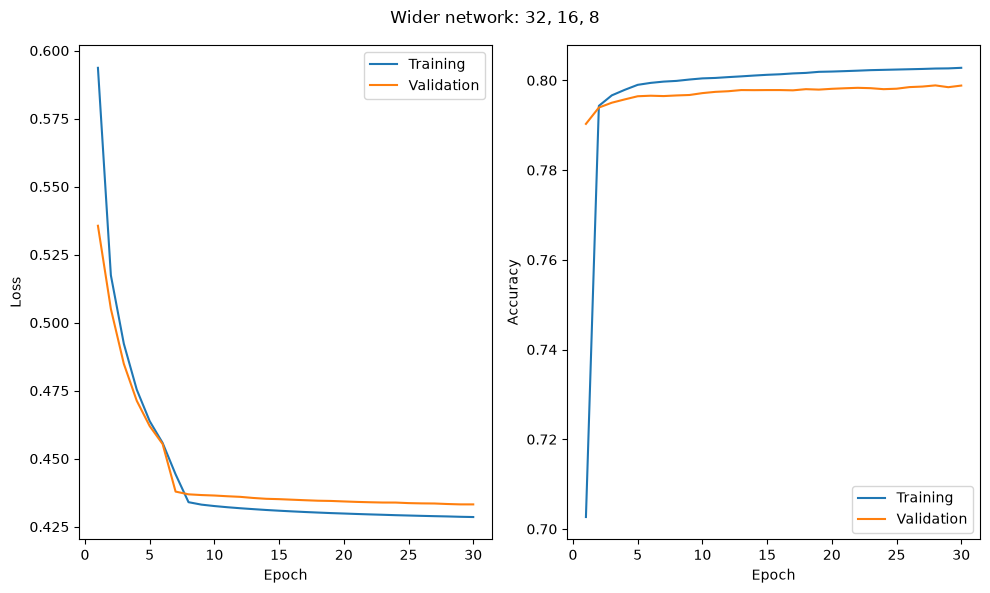

Wider network validation AUC:  0.8725462761015084


In [42]:
#Training the wider model
keras.utils.set_random_seed(42)

wide_model = build_dnn(X_Train.shape[1], [32,16,8])

wide_history = wide_model.fit(
    X_Train,
    y_Train,
    validation_data = (X_Val, y_Val),
    epochs = 30,
    batch_size = 2048
)

plot_history(wide_history, "Wider network: 32, 16, 8")

wide_val_scores = wide_model.predict(X_Val, batch_size = 2048, verbose = 0).ravel()

#false positive and true negatives
fpr_wide, tpr_wide, thresholds_wide = roc_curve(y_Val, wide_val_scores)
auc_wide = auc(fpr_wide, tpr_wide)

print("Wider network validation AUC: ", auc_wide)

Epoch 1/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7784 - loss: 0.4693 - val_accuracy: 0.7931 - val_loss: 0.4440
Epoch 2/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7979 - loss: 0.4380 - val_accuracy: 0.7956 - val_loss: 0.4395
Epoch 3/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7992 - loss: 0.4352 - val_accuracy: 0.7964 - val_loss: 0.4375
Epoch 4/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7997 - loss: 0.4338 - val_accuracy: 0.7961 - val_loss: 0.4364
Epoch 5/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8003 - loss: 0.4328 - val_accuracy: 0.7967 - val_loss: 0.4356
Epoch 6/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8007 - loss: 0.4320 - val_accuracy: 0.7970 - val_loss: 0.4350
Epoch 7/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8010 - loss: 0.4314 - val_accuracy: 0.7978 - val_loss: 0.4346
Epoch 8/30
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8013 - loss: 0.4310 - val_accuracy: 0.

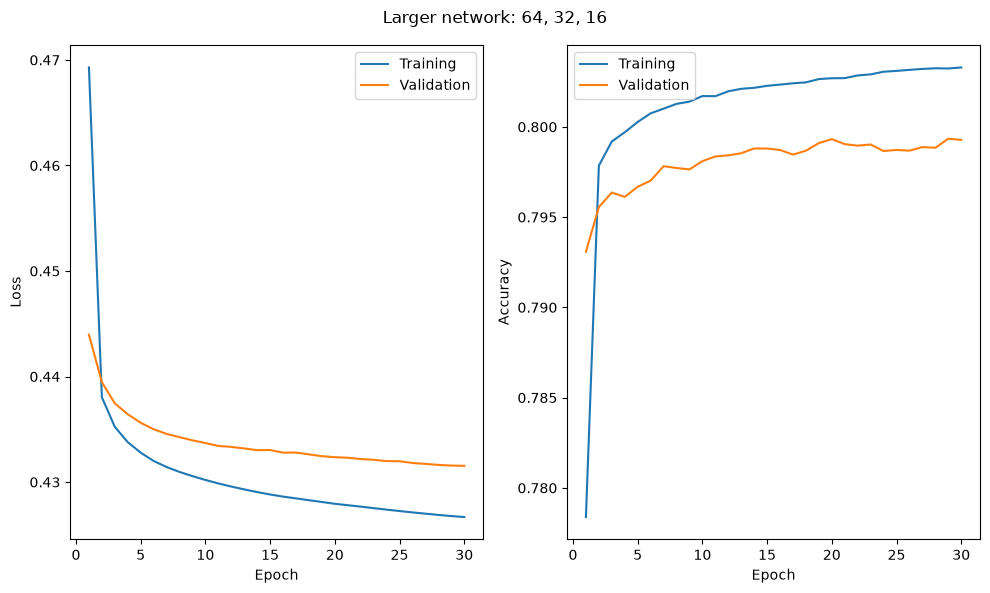

Large network validation AUC:  0.8736255173802958


In [44]:
#training the larger architecture model with more number of hudden layers(64,32,16)

# keras.utils.set_random_seed(42)
large_model = build_dnn(X_Train.shape[1], [64, 32, 16])
large_history = large_model.fit(
    X_Train,
    y_Train,
    validation_data = (X_Val, y_Val),
    epochs = 30,
    batch_size = 2048
)

plot_history(large_history, "Larger network: 64, 32, 16")

large_val_scores = large_model.predict(X_Val, batch_size = 2048, verbose = 0).ravel()

#false positives and true positives
fpr_large, tpr_large, thresholds_large = roc_curve(y_Val, large_val_scores)
auc_large = auc(fpr_large, tpr_large)

print(f"Large network validation AUC: ", auc_large)


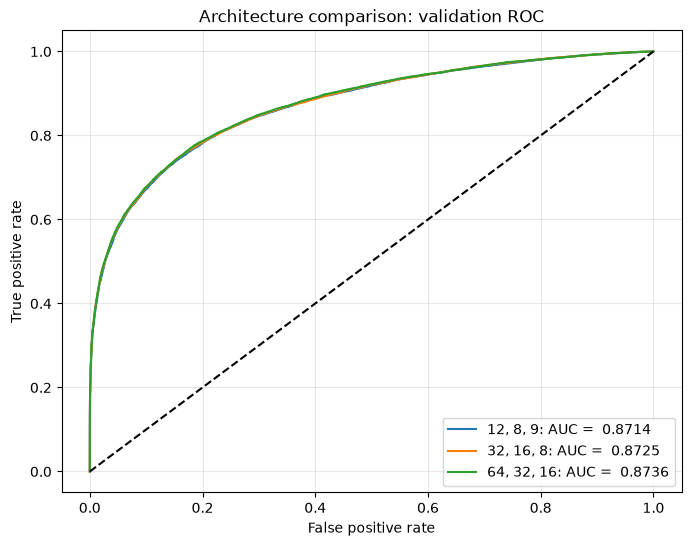

In [46]:
#comparison curves
plt.figure(figsize = (8, 6))

plt.plot(fpr_all, tpr_all, label = f"12, 8, 9: AUC = {auc_all: .4f}")
plt.plot(fpr_wide, tpr_wide, label = f"32, 16, 8: AUC = {auc_wide: .4f}")
plt.plot(fpr_large, tpr_large, label = f"64, 32, 16: AUC = {auc_large: .4f}")

plt.plot([0,1],[0,1], "k--")

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Architecture comparison: validation ROC")
plt.legend(loc = "best")
plt.grid(alpha=0.3)
plt.show()

In [47]:
#saving for next exercise
best_dnn = large_model

Increasing the hidden layer sizes slightly improved validation AUC, from 0.8714 to 0.8736. The larger network showed a training-validation gap, although validation loss continued to decrease slowly. I have selected the 64, 32, 16 network based on its highest validation AUC among the tested models. 

## Exercise 4

Repeat Exercise 4 from Lab 8 (parts b and c), adding your best performing DNN as one of the models. Choose your best DNN using the validation sample, then compare on the test sample.

In [48]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

feature_groups = {
    "Raw": RawNames,
    "Engineered": FeatureNames,
    "All": VarNames[1:]
}

classifiers = {
    "Decision tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=100,
        random_state=42
    ),
    "Logistic regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "Gradient boosting": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    )
}

comparison_results = {}

Decision tree Raw | Validation AUC: 0.8371 | Test AUC: 0.8369
Decision tree Engineered | Validation AUC: 0.8185 | Test AUC: 0.8196
Decision tree All | Validation AUC: 0.8407 | Test AUC: 0.8419


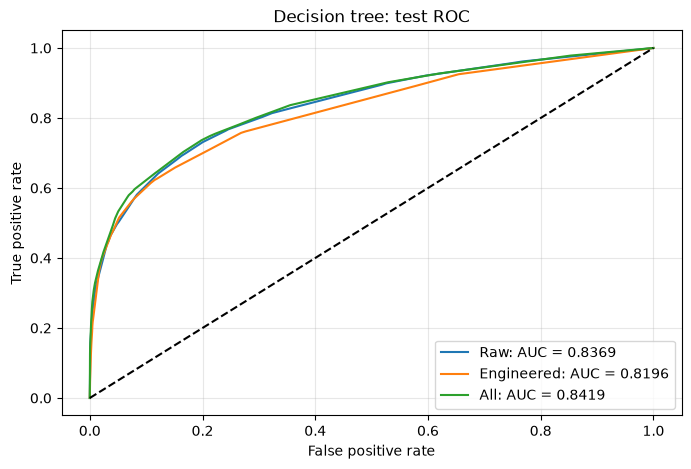

Logistic regression Raw | Validation AUC: 0.8308 | Test AUC: 0.8311
Logistic regression Engineered | Validation AUC: 0.8313 | Test AUC: 0.8349
Logistic regression All | Validation AUC: 0.8565 | Test AUC: 0.8598


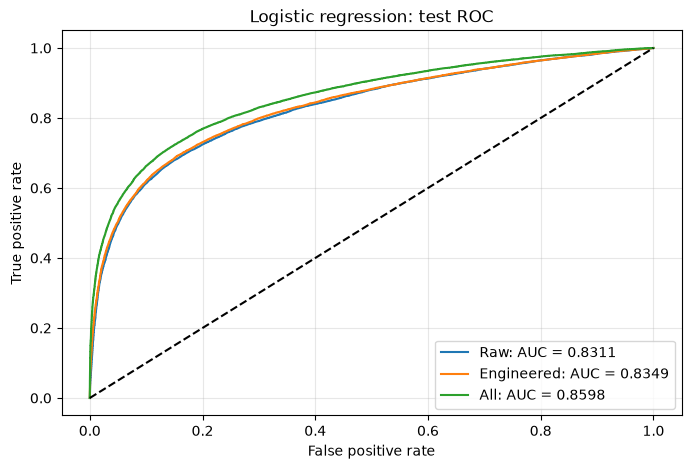

Gradient boosting Raw | Validation AUC: 0.8586 | Test AUC: 0.8603
Gradient boosting Engineered | Validation AUC: 0.8595 | Test AUC: 0.8633
Gradient boosting All | Validation AUC: 0.8727 | Test AUC: 0.8760


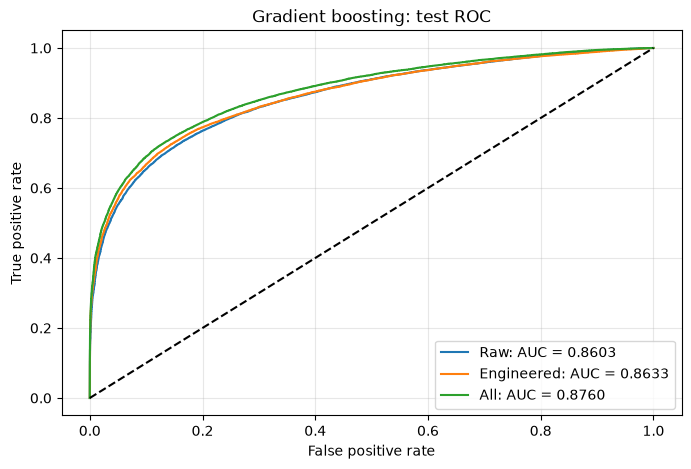

In [49]:
for classifier_name, classifier in classifiers.items():
    plt.figure(figsize=(8, 5))

    for group_name, columns in feature_groups.items():
        trained_model = clone(classifier)

        trained_model.fit(
            Train_Sample[columns].to_numpy(), y_Train
        )

        val_scores = trained_model.predict_proba(
            Val_Sample[columns].to_numpy()
        )[:, 1]

        test_scores = trained_model.predict_proba(
            Test_Sample[columns].to_numpy()
        )[:, 1]

        val_fpr, val_tpr, _ = roc_curve(y_Val, val_scores)
        test_fpr, test_tpr, _ = roc_curve(y_Test, test_scores)

        val_auc = auc(val_fpr, val_tpr)
        test_auc = auc(test_fpr, test_tpr)

        comparison_results[(classifier_name, group_name)] = {
            "model": trained_model,
            "val_scores": val_scores,
            "test_scores": test_scores,
            "val_auc": val_auc,
            "test_auc": test_auc
        }

        plt.plot(
            test_fpr, test_tpr,
            label=f"{group_name}: AUC = {test_auc:.4f}"
        )

        print(
            classifier_name, group_name,
            f"| Validation AUC: {val_auc:.4f}",
            f"| Test AUC: {test_auc:.4f}"
        )

    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"{classifier_name}: test ROC")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

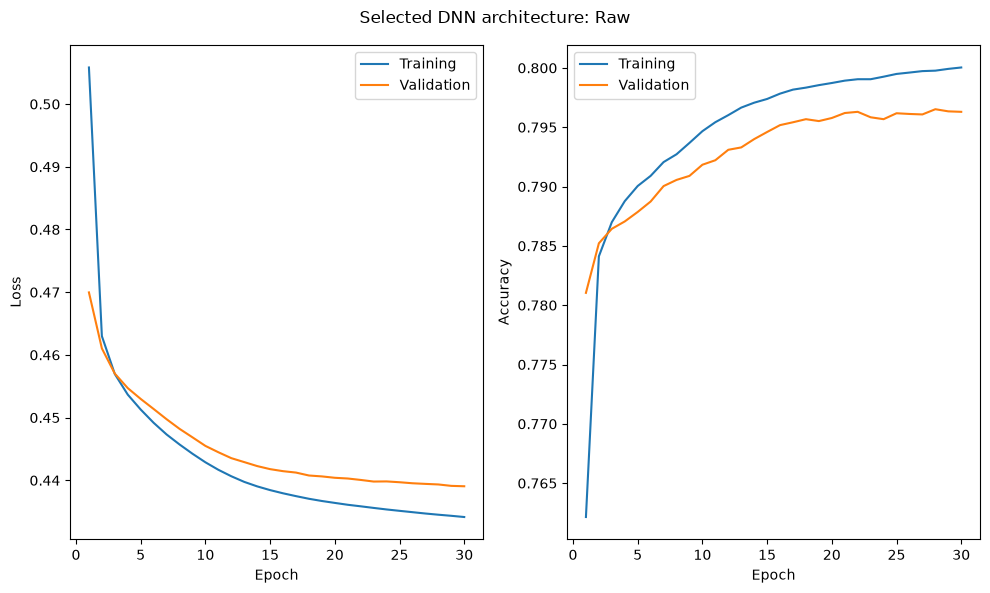

Raw | Validation AUC: 0.8687 | Test AUC: 0.8727


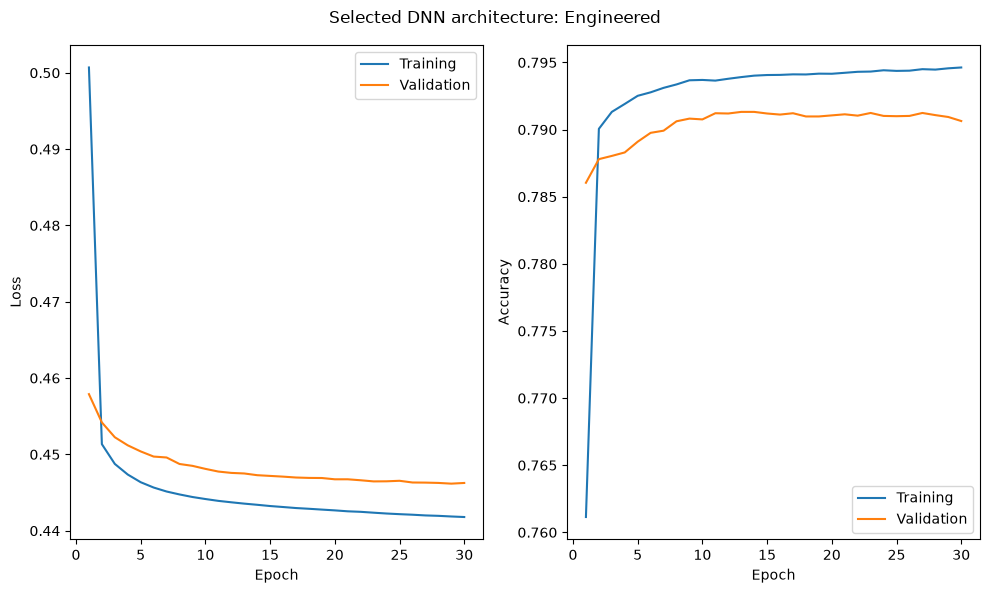

Engineered | Validation AUC: 0.8631 | Test AUC: 0.8672
All | Validation AUC: 0.8736 | Test AUC: 0.8776


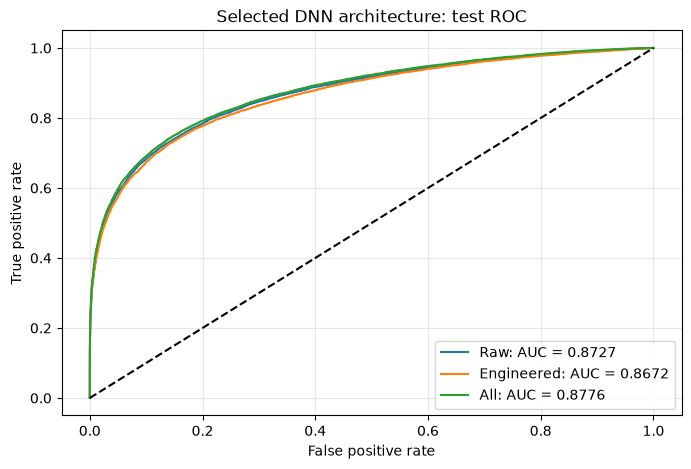

In [50]:
dnn_test_curves = {}

for group_name, columns in feature_groups.items():
    train_x = Train_Sample[columns].to_numpy()
    val_x = Val_Sample[columns].to_numpy()
    test_x = Test_Sample[columns].to_numpy()

    if group_name == "All":
        trained_model = best_dnn  # Already trained in Exercise 3
    else:
        keras.utils.set_random_seed(42)
        trained_model = build_dnn(len(columns), [64, 32, 16])

        group_history = trained_model.fit(
            train_x,
            y_Train,
            validation_data=(val_x, y_Val),
            epochs=30,
            batch_size=2048,
            verbose=0
        )

        plot_history(
            group_history,
            f"Selected DNN architecture: {group_name}"
        )

    val_scores = trained_model.predict(
        val_x, batch_size=2048, verbose=0
    ).ravel()

    test_scores = trained_model.predict(
        test_x, batch_size=2048, verbose=0
    ).ravel()

    val_fpr, val_tpr, _ = roc_curve(y_Val, val_scores)
    test_fpr, test_tpr, _ = roc_curve(y_Test, test_scores)

    val_auc = auc(val_fpr, val_tpr)
    test_auc = auc(test_fpr, test_tpr)

    comparison_results[("DNN", group_name)] = {
        "model": trained_model,
        "val_scores": val_scores,
        "test_scores": test_scores,
        "val_auc": val_auc,
        "test_auc": test_auc
    }

    dnn_test_curves[group_name] = (test_fpr, test_tpr, test_auc)

    print(
        group_name,
        f"| Validation AUC: {val_auc:.4f}",
        f"| Test AUC: {test_auc:.4f}"
    )

plt.figure(figsize=(8, 5))

for group_name, (fpr, tpr, score) in dnn_test_curves.items():
    plt.plot(fpr, tpr, label=f"{group_name}: AUC = {score:.4f}")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Selected DNN architecture: test ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [51]:
comparison_table = pd.DataFrame([
    {
        "Classifier": name,
        "Features": group,
        "Validation AUC": result["val_auc"],
        "Test AUC": result["test_auc"]
    }
    for (name, group), result in comparison_results.items()
])

display(comparison_table.round(4))

,Classifier,Features,Validation AUC,Test AUC
0,Decision tree,Raw,0.8371,0.8369
1,Decision tree,Engineered,0.8185,0.8196
2,Decision tree,All,0.8407,0.8419
3,Logistic regression,Raw,0.8308,0.8311
4,Logistic regression,Engineered,0.8313,0.8349
5,Logistic regression,All,0.8565,0.8598
6,Gradient boosting,Raw,0.8586,0.8603
7,Gradient boosting,Engineered,0.8595,0.8633
8,Gradient boosting,All,0.8727,0.8760
9,DNN,Raw,0.8687,0.8727


The DNN using all 18 features achieved the highest validation AUC of 0.8736 and test AUC of 0.8776. Gradient boosting performed similarly, with a test AUC of 0.8760. Combining raw and engineered features improved performance for all four classifiers.

In [52]:
# Selecting the classifier and feature group using validation AUC
best_key = max(
    comparison_results,
    key=lambda key: comparison_results[key]["val_auc"]
)

best_result = comparison_results[best_key]
print("Selected model:", best_key)

# Considering every available validation-score threshold
val_fpr, val_tpr, val_thresholds = roc_curve(
    y_Val,
    best_result["val_scores"],
    drop_intermediate=False
)

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

significance_results = []

for initial_signal, initial_background in scenarios:
    # Expected validation yields at each threshold
    signal_val = initial_signal * val_tpr
    background_val = initial_background * val_fpr
    total_val = signal_val + background_val

    significance_val = np.zeros_like(total_val)
    valid = total_val > 0

    significance_val[valid] = (
        signal_val[valid] / np.sqrt(total_val[valid])
    )

    # Choosing the threshold using validation data
    best_index = np.argmax(significance_val)
    best_threshold = val_thresholds[best_index]

    # Applying that fixed threshold to the test sample
    selected = best_result["test_scores"] >= best_threshold

    signal_efficiency = selected[y_Test == 1].mean()
    background_efficiency = selected[y_Test == 0].mean()

    signal_test = initial_signal * signal_efficiency
    background_test = initial_background * background_efficiency

    total_test = signal_test + background_test
    test_significance = (
        signal_test / np.sqrt(total_test)
        if total_test > 0 else 0.0
    )

    significance_results.append({
        "Initial signal": initial_signal,
        "Initial background": initial_background,
        "Chosen threshold": best_threshold,
        "Max validation significance": significance_val[best_index],
        "Test signal efficiency": signal_efficiency,
        "Test background efficiency": background_efficiency,
        "Expected test signal": signal_test,
        "Expected test background": background_test,
        "Test significance": test_significance
    })

significance_table = pd.DataFrame(significance_results)
display(significance_table.round(4))

Selected model: ('DNN', 'All')


,Initial signal,Initial background,Chosen threshold,Max validation significance,Test signal efficiency,Test background efficiency,Expected test signal,Expected test background,Test significance
0,10,100,0.8327,1.8187,0.483,0.0201,4.8302,2.0074,1.8472
1,100,1000,0.8327,5.7513,0.483,0.0201,48.3020,20.0737,5.8414
2,1000,10000,0.8327,18.1873,0.483,0.0201,483.0197,200.7366,18.4720
3,10000,100000,0.8327,57.5134,0.483,0.0201,4830.1969,2007.3665,58.4136


I selected the DNN with all features using validation AUC. The threshold chosen by maximizing validation significance was 0.8327. Applied to the test sample, it retained 48.30% of signal and 2.01% of background. Test significance increased from 1.8472 to 58.4136 across the four scenarios. The threshold remained unchanged because all scenarios had the same initial signal-to-background ratio.